# Week 2 - Monday: Data Preprocessing, Train/Test Split and Cross-Validation

**Dataset:** Titanic (from seaborn)

**Goal:** clean the Titanic data and compare a single train/test split with cross-validation.

**Done when:** I can clean Titanic and explain why the imputer is fitted only on the training data.

---
### Quick theory
- **Train/test split:** the model learns from the training set and is checked on unseen test data.
- **Data leakage:** information from the test set influences training. Never fit imputers, scalers or encoders on test data.
- **Cross-validation (k-fold):** train and test k times on different parts of the data, then average the scores. More reliable than one split.
- **Missing data:** drop the column if mostly missing, otherwise fill (mean, median or most frequent).
- **Encoding:** one-hot for unordered categories, ordinal for ordered ones.
- **Scaling:** StandardScaler (mean 0, std 1) or MinMaxScaler (0 to 1). Needed for distance-based models such as kNN.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

sns.set_theme(style="whitegrid")

## Step 1: Load Titanic and explore the data (EDA)

In [2]:
df = sns.load_dataset("titanic")
print("Shape:", df.shape)
df.head()

Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


**Numeric vs categorical columns.** Numbers (`int64`, `float64`) are numeric. Text/category columns (`str`, `object`, `category`) are categorical.

In [3]:
df.dtypes

survived          int64
pclass            int64
sex                 str
age             float64
sibsp             int64
parch             int64
fare            float64
embarked            str
class          category
who                 str
adult_male         bool
deck           category
embark_town         str
alive               str
alone              bool
dtype: object

**Missing values.** `deck` is mostly missing, `age` has some missing, `embarked` has only 2.

age            177
embarked         2
deck           688
embark_town      2
dtype: int64


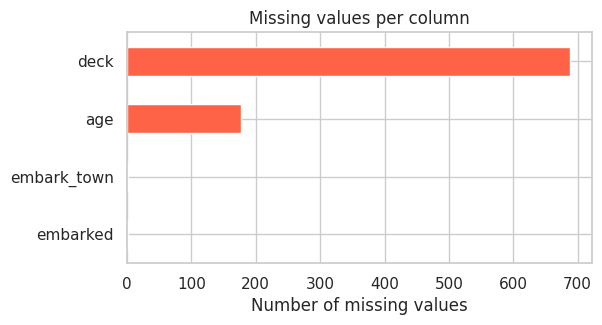

In [4]:
missing = df.isnull().sum()
print(missing[missing > 0])

missing[missing > 0].sort_values().plot(kind="barh", color="tomato", figsize=(6, 3))
plt.title("Missing values per column")
plt.xlabel("Number of missing values")
plt.show()

**Survival rate overall, by sex and by class.**

In [5]:
print("Overall survival rate:", round(df["survived"].mean(), 3))
print()
print("By sex:");   print(df.groupby("sex")["survived"].mean().round(3))
print()
print("By class:"); print(df.groupby("pclass")["survived"].mean().round(3))

Overall survival rate: 0.384

By sex:
sex
female    0.742
male      0.189
Name: survived, dtype: float64

By class:
pclass
1    0.630
2    0.473
3    0.242
Name: survived, dtype: float64


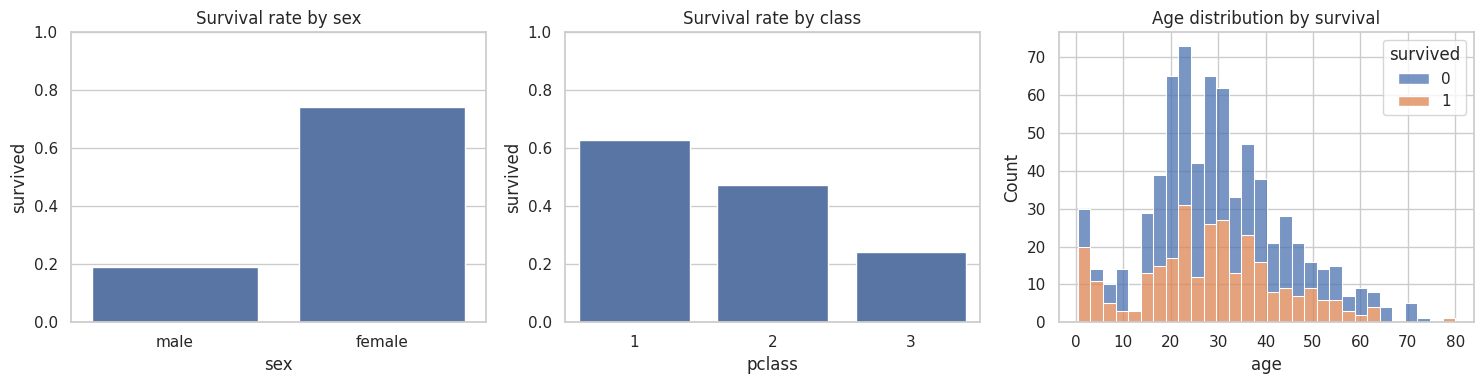

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.barplot(data=df, x="sex", y="survived", ax=axes[0], errorbar=None)
axes[0].set_title("Survival rate by sex")
axes[0].set_ylim(0, 1)

sns.barplot(data=df, x="pclass", y="survived", ax=axes[1], errorbar=None)
axes[1].set_title("Survival rate by class")
axes[1].set_ylim(0, 1)

sns.histplot(data=df, x="age", hue="survived", bins=30, multiple="stack", ax=axes[2])
axes[2].set_title("Age distribution by survival")

plt.tight_layout()
plt.show()

**What we see:** women survived far more than men, and first class far more than third class. So `sex` and `pclass` are strong features.

## Step 2: Decide how to handle missing values

| Column | Missing | Decision |
|---|---|---|
| `deck` | 688 of 891 | **Drop** (mostly missing) |
| `age` | 177 | Fill with **median** (robust to outliers) |
| `embarked` | 2 | Fill with **most frequent** value |

The filling is done with `SimpleImputer` inside a Pipeline (Step 3), so it is fitted on training data only.

In [7]:
df = df.drop(columns=["deck"])

X = df[["age", "fare", "pclass", "sex", "embarked"]]
y = df["survived"]

numeric_cols = ["age", "fare", "pclass"]
categorical_cols = ["sex", "embarked"]

X.head()

,age,fare,pclass,sex,embarked
0,22.0,7.2500,3,male,S
1,38.0,71.2833,1,female,C
2,26.0,7.9250,3,female,S
3,35.0,53.1000,1,female,S
4,35.0,8.0500,3,male,S


## Step 3: Encode categories and scale numbers

- Numeric columns: `SimpleImputer(median)` then `StandardScaler`
- Categorical columns: `SimpleImputer(most_frequent)` then `OneHotEncoder`

`ColumnTransformer` applies the right steps to the right columns, and `Pipeline` chains the preprocessing with the model.

In [8]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_cols),
    ]
)

model = Pipeline([
    ("preprocess", preprocessor),
    ("clf", LogisticRegression(max_iter=1000)),
])
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contai

## Step 4: Train/test split vs cross-validation

`stratify=y` keeps the survived/not-survived ratio the same in train and test.

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

model.fit(X_train, y_train)
single_split_score = model.score(X_test, y_test)
print("Single split accuracy:", round(single_split_score, 4))

# Look at what the preprocessing produced (fitted on training data only)
names = model.named_steps["preprocess"].get_feature_names_out()
print("\nFeatures after preprocessing:", list(names))

Single split accuracy: 0.7709

Features after preprocessing: ['num__age', 'num__fare', 'num__pclass', 'cat__sex_female', 'cat__sex_male', 'cat__embarked_C', 'cat__embarked_Q', 'cat__embarked_S']


In [10]:
cv_scores = cross_val_score(model, X, y, cv=5)

print("5-fold CV scores:", [round(float(s), 4) for s in cv_scores])
print("5-fold CV mean  :", round(cv_scores.mean(), 4))
print("5-fold CV std   :", round(cv_scores.std(), 4))

5-fold CV scores: [0.7765, 0.7865, 0.7753, 0.7697, 0.7921]
5-fold CV mean  : 0.78
5-fold CV std   : 0.0081


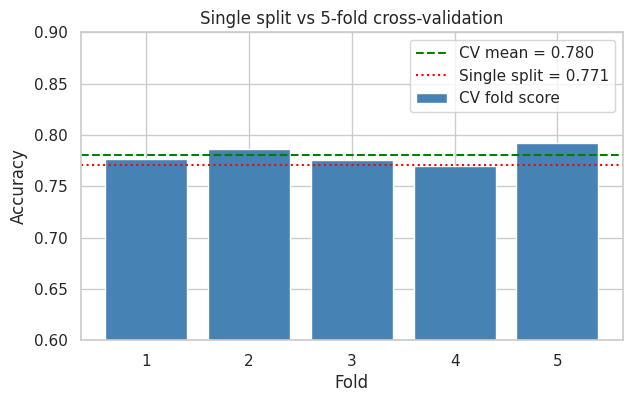

In [11]:
plt.figure(figsize=(7, 4))
plt.bar(range(1, 6), cv_scores, color="steelblue", label="CV fold score")
plt.axhline(cv_scores.mean(), color="green", linestyle="--", label=f"CV mean = {cv_scores.mean():.3f}")
plt.axhline(single_split_score, color="red", linestyle=":", label=f"Single split = {single_split_score:.3f}")
plt.ylim(0.6, 0.9)
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.title("Single split vs 5-fold cross-validation")
plt.legend()
plt.show()

**Reading the graph:** each fold gives a slightly different score. The single split (red) is just one of many possible results, while the CV mean (green) averages all five. The standard deviation is small, so the model is stable.

## Why is the imputer fitted only on the training data?

If we fitted the imputer (or scaler) on the whole dataset, the median age would include test passengers. Information from the test set would leak into training, and the test score would look better than it really is.

Because everything is inside a `Pipeline`, `fit` learns the median, mean and categories from the training data only, and `cross_val_score` refits the preprocessing on each training fold. The test fold stays unseen.

---
## Notes (Monday)
- **Data leakage:** test-set information influencing training. Fit preprocessing on train only.
- **Why CV is more reliable:** it averages several splits instead of depending on one lucky or unlucky split, and the std shows stability.
- **Impute vs drop:** drop a column if mostly missing (`deck`); impute when only some values are missing (`age`, `embarked`).
- **One-hot vs ordinal:** one-hot for unordered categories (`sex`, `embarked`); ordinal for ordered ones (low < medium < high).

## My results
| Method | Accuracy |
|---|---|
| Single split | 0.7709 |
| 5-fold CV mean | 0.78 (std 0.008) |